# 제시 라벨과 일치율

**이 노트북에서 할 일**

1. 답 네 개에 교재 작성자가 근거 충실도 제시 라벨을 적습니다.
2. 라벨과 판정의 짝을 네 칸으로 세고 일치율을 내는 함수를 만듭니다.
3. 평가 모델(judge)에게 판정 머리글 두 판으로 판정을 받아 라벨과 견줍니다.
4. 언제나 1을 적는 규칙 함수와 견주어 일치율 하나만 볼 때의 한계를 봅니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
평가 모델 `gpt-5.4-mini`에 보내는 요청은 여덟 번이고 임베딩 요청은 없습니다.
판정 머리글 두 판으로 답 네 개를 한 번씩 판정합니다.
예상 비용은 미화 0.05달러 아래이고 실제 청구 금액과는 다를 수 있습니다.

읽는 파일은 이 챕터 자료 파일 하나이고 새로 쓰는 파일은 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 약 9초 만에 끝났습니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~7절을 읽습니다.
제시 라벨을 적고 네 칸 표로 평가 모델 판정과 견주는 자리입니다.
8절은 판정 머리글 판을 바꿔 일치율을 다시 셉니다.
9절은 값 바꿔 보기이고 8절과 함께 실습 시간에 실행합니다.

실습 폴더 `labs/part4/ch15-evaluation-advanced`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위쪽에 칸 둘이 나란히 있고 아래로 상자 둘이 이어지는 그림으로 왼쪽 칸 교재 작성자 눈금에는 초록 상자 답 네 개 자료 답 셋 바꾼 답 하나에서 초록 상자 제시 라벨 판정을 받기 전에 적음으로 이어지고 오른쪽 칸 평가 모델 저울에는 초록 상자 같은 답 네 개에서 보라 상자 평가 모델 gpt-5.4-mini 판정 머리글 두 판을 지나 노란 상자 점수 0 또는 1로 이어지며 두 칸이 파란 상자 box_name count_boxes 답마다 라벨과 점수를 짝지어 네 칸에 세기로 모이고 맨 아래 노란 상자 네 칸 표와 일치율 둘 다 1 둘 다 0 라벨 0 판정 1 라벨 1 판정 0으로 끝나는 그림](attachment:04-1-라벨과-판정을-네-칸으로.png)

위쪽 왼쪽 칸은 교재 작성자가 판정 전에 적는 제시 라벨입니다.
오른쪽 칸은 같은 답을 평가 모델에 보내 받는 점수입니다.
두 칸이 파란 상자에서 만나 답마다 짝지어지고 맨 아래 노란 상자가 네 칸 표와 일치율입니다.
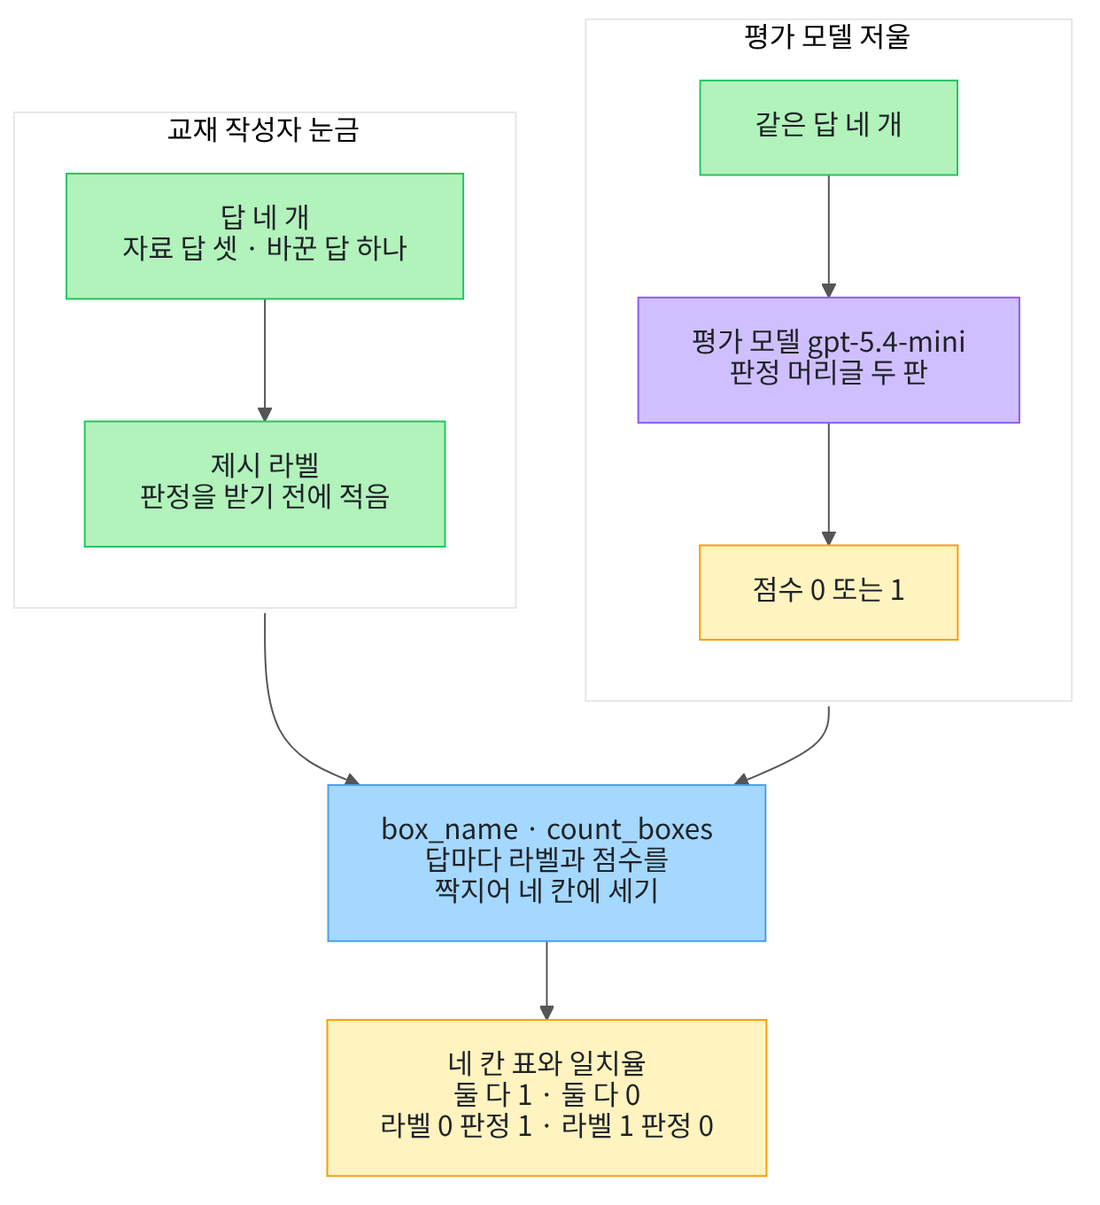

## 1. 준비

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.1`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-21에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 불러오고 03절 함수 하나를 도구 파일에서 가져옵니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 03절 `score_cases()`를 가져옵니다.
함수 안에서 부르는 02절 함수 둘도 같은 파일에 있습니다.

In [2]:
# 자료 읽기·폴더 확인에 쓸 이름과 모델을 준비하는 이름을 불러옵니다
import json
import os

from langchain.chat_models import init_chat_model

# Ch 15 03절에서 배운 함수 하나를 도구 파일에서 가져옵니다
from rag_tools import score_cases

print("불러온 이름:", "json", "os", "init_chat_model")

불러온 이름: json os init_chat_model


**결과 읽기** — 출력 줄 `불러온 이름: json os init_chat_model`로 이름 세 개를 불러왔습니다.
도구 파일에서 가져온 함수 `score_cases`는 출력하지 않습니다.
이 함수는 03절에서 쓰던 인자 그대로입니다.

## 2. 키와 모델 준비

이 절도 02·03절과 같은 평가 모델 `gpt-5.4-mini`를 부릅니다.
모델을 만드는 설정 값도 03절과 같습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도 판정 글이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

## 3. 평가 사례와 기준 답

먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.
01~03절과 같은 자리 찾기 셀입니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch15-evaluation-advanced/data"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위:` 뒤에 점 하나나 위로 올라가는 자리가 보입니다.

다음 셀은 03절과 같은 방법으로 이 챕터 자료 파일을 읽습니다.

In [6]:
# 이 챕터 자료 파일을 읽어 평가 사례 목록과 질문 번호 목록을 만듭니다(읽기만 합니다)
data_path = root_path + "/labs/part4/ch15-evaluation-advanced/data"
with open(data_path + "/evaluation-cases.json", encoding="utf-8") as file:
    case_file = json.loads(file.read())
cases = case_file["cases"]
case_qids = []
for case in cases:
    case_qids.append(case["qid"])
print("평가 사례 수:", len(cases))
print("평가 사례의 질문 번호:", case_qids)

평가 사례 수: 3
평가 사례의 질문 번호: ['Q002', 'Q006', 'Q090']


**결과 읽기** — 출력 줄 `평가 사례 수: 3`으로 사례는 세 건입니다.
출력 줄 `평가 사례의 질문 번호: ['Q002', 'Q006', 'Q090']`도 03절과 같습니다.

라벨을 적으려면 무엇을 맞는 답으로 볼지 먼저 알아야 합니다.
다음 셀은 자료 파일에 적힌 기준 답과 그 출처를 봅니다.
사례 칸에 라벨이 이미 있는지도 찾아봅니다.

In [7]:
# 세 사례의 기준 답과 그 출처를 보고, 사례 칸 가운데 라벨 칸이 있는지 찾습니다
print("질문 번호 | 기준 답 출처 | 기준 답")
for case in cases:
    print(case["qid"], "|", case["reference_kind"], "|", case["reference_answer"])
label_keys = []
for key in cases[0]:
    if "label" in key:
        label_keys.append(key)
print("이름에 label이 든 칸:", label_keys)

질문 번호 | 기준 답 출처 | 기준 답
Q002 | 교육용 작성자 기준 | 도서는 한 번에 7권까지 14일 동안 빌릴 수 있습니다.
Q006 | 교육용 작성자 기준 | 회원은 최초 2시간 무료이며 이후 30분마다 500원입니다.
Q090 | 교육용 작성자 기준 | 제공된 본문에는 입회인 정보가 없어 확인할 수 없습니다.
이름에 label이 든 칸: []


**결과 읽기** — 라벨 줄 `질문 번호 | 기준 답 출처 | 기준 답` 아래 세 줄이 자료 파일의 기준 답입니다.
세 줄 모두 출처가 `교육용 작성자 기준`이라 교재 작성자가 적은 글입니다.
출력 줄 `이름에 label이 든 칸: []`으로 사례 칸에는 라벨 칸이 없습니다.

그래서 라벨은 이 절에서 교재 작성자가 적습니다.
사례 Q090의 기준 답은 입회인 정보가 없어 확인할 수 없다는 글입니다.
교재 작성자는 없다고 답하는 것을 이 사례의 맞는 답으로 정해 두었습니다.

## 4. 제시 라벨 적기

교재 작성자가 보기에 세 사례의 답은 모두 기준 답과 같은 뜻입니다.
라벨이 모두 1이면 평가 모델이 틀린 답을 0으로 잡는지 볼 수 없습니다.
그래서 이 절에서 틀린 답 하나를 만들어 함께 판정합니다.
사례 Q002의 답에서 권수와 기간만 02절 값 바꿔 보기의 숫자로 바꿉니다.

In [8]:
# 사례 Q002의 답에서 권수와 기간만 틀리게 바꾼 답 하나를 이 절에서 만듭니다(02절 값 바꿔 보기의 숫자)
first_case = cases[0]
changed_case = {}
changed_case["qid"] = "Q002-바꾼 답"
changed_case["response"] = "도서는 한 번에 5권까지 빌릴 수 있고, 대출 기간은 7일입니다. [E01]"
changed_case["context"] = first_case["context"]
print("자료 답:", first_case["response"])
print("바꾼 답:", changed_case["response"])
print("근거 문서에 '도서 7권'이 있는가:", "도서 7권" in first_case["context"])
print("근거 문서에 '도서 14일'이 있는가:", "도서 14일" in first_case["context"])

자료 답: 도서는 한 번에 7권까지 빌릴 수 있고, 대출 기간은 14일입니다. [E01]
바꾼 답: 도서는 한 번에 5권까지 빌릴 수 있고, 대출 기간은 7일입니다. [E01]
근거 문서에 '도서 7권'이 있는가: True
근거 문서에 '도서 14일'이 있는가: True


**결과 읽기** — 출력 줄 `자료 답:`과 `바꾼 답:`을 견주면 숫자 두 개만 다릅니다.
출력 줄 `근거 문서에 '도서 7권'이 있는가: True`로 문서는 도서를 7권까지라고 말합니다.
기간도 출력 줄 `근거 문서에 '도서 14일'이 있는가: True`처럼 14일입니다.

바꾼 답은 이 절에서 만든 글이고 자료 파일에는 없습니다.
칸은 판정에 쓰는 세 칸(`qid`·`response`·`context`)만 두었습니다.
칸 `qid`에는 질문 번호 대신 이름 `Q002-바꾼 답`을 적어 자료 답과 가릅니다.
다음 셀은 자료 답 세 개와 바꾼 답을 한 목록에 모읍니다.

In [9]:
# 라벨을 붙일 답 네 개를 한 목록에 모읍니다(평가 사례 세 건의 자료 답 + 이 절에서 바꾼 답 하나)
label_cases = []
for case in cases:
    label_cases.append(case)
label_cases.append(changed_case)
label_names = []
for case in label_cases:
    label_names.append(case["qid"])
print("라벨을 붙일 답:", label_names)

라벨을 붙일 답: ['Q002', 'Q006', 'Q090', 'Q002-바꾼 답']


**결과 읽기** — 출력 줄 `라벨을 붙일 답:` 뒤에 이름 네 개가 보입니다.
앞의 셋은 자료 파일 사례의 답이고 마지막 `Q002-바꾼 답`은 이 절에서 만든 답입니다.
이 절에서 평가 사례는 자료 파일의 세 건만 가리킵니다.
넷을 함께 부를 때는 답 네 개라고 부르겠습니다.

다음 셀에서 답마다 제시 라벨을 적습니다.
라벨 기준은 근거 충실도입니다.
답이 근거 문서에 있는 사실만 말하면 1, 문서와 다른 사실을 말하면 0입니다.
문서에 없는 정보를 없다고 말한 답은 1로 적습니다.

In [10]:
# 근거 충실도 기준으로 교재 작성자가 답마다 0이나 1을 적습니다(판정을 받기 전에 적습니다)
given_labels = {}
given_labels["Q002"] = 1
given_labels["Q006"] = 1
given_labels["Q090"] = 1
given_labels["Q002-바꾼 답"] = 0
print("라벨 출처: 이 절에서 교재 작성자가 적은 라벨")
print("이름 | 제시 라벨")
for name in given_labels:
    print(name, "|", given_labels[name])

라벨 출처: 이 절에서 교재 작성자가 적은 라벨
이름 | 제시 라벨
Q002 | 1
Q006 | 1
Q090 | 1
Q002-바꾼 답 | 0


**결과 읽기** — 출력 줄 `라벨 출처: 이 절에서 교재 작성자가 적은 라벨`이 이 라벨의 출처입니다.
라벨 줄 `이름 | 제시 라벨` 아래 네 줄이 답마다 적은 값입니다.
자료 답 셋은 `Q090 | 1`처럼 모두 1이고 바꾼 답은 `Q002-바꾼 답 | 0`입니다.

이 라벨은 사람 여럿이 따로 매긴 것이 아닙니다.
교재 작성자 한 사람이 기준 답과 근거 문서를 보고 적은 값입니다.
평가 모델 판정은 아직 한 번도 받지 않았습니다.
라벨을 판정보다 먼저 적어야 판정에 맞춰 라벨을 고치는 일을 막을 수 있습니다.

## 5. 네 칸 표와 일치율

라벨과 판정은 모두 0이나 1이라 짝은 네 가지뿐입니다.
둘 다 1, 둘 다 0, 라벨 0인데 판정 1, 라벨 1인데 판정 0입니다.
네 칸에 답이 몇 개씩 들어가는지 센 표를 네 칸 표(혼동 행렬, confusion matrix)라고 합니다.
다음 셀은 라벨과 점수 한 쌍이 어느 칸인지 이름을 내는 함수입니다.

In [11]:
# 라벨과 점수 한 쌍이 네 칸 가운데 어느 칸에 들어가는지 칸 이름을 냅니다
def box_name(label, score):
    if label == 1 and score == 1:
        return "둘 다 1"
    if label == 0 and score == 0:
        return "둘 다 0"
    if label == 0:
        return "라벨 0 · 판정 1"
    return "라벨 1 · 판정 0"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `box_name`은 라벨과 점수를 받아 네 칸 가운데 한 이름을 냅니다.
위에서부터 둘 다 1인지, 둘 다 0인지를 먼저 봅니다.
그 밖에 라벨이 0이면 판정이 1인 칸이고, 나머지는 라벨 1에 판정 0인 칸입니다.

다음 셀은 이름마다 라벨과 점수를 짝지어 네 칸을 세는 함수입니다.

In [12]:
# 이름마다 라벨과 점수를 짝지어 네 칸에 몇 개씩 들어가는지 셉니다(네 칸 모두 0에서 시작합니다)
def count_boxes(labels, scores):
    box_counts = {"둘 다 1": 0, "둘 다 0": 0, "라벨 0 · 판정 1": 0, "라벨 1 · 판정 0": 0}
    for name in labels:
        box = box_name(labels[name], scores[name])
        box_counts[box] = box_counts[box] + 1
    return box_counts

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `count_boxes`는 이름별 라벨 딕셔너리와 이름별 점수 딕셔너리를 받습니다.
네 칸을 모두 0으로 두고 시작해 이름마다 들어갈 칸에 1을 더합니다.
들어간 답이 없는 칸도 0으로 남아 네 칸이 늘 모두 보입니다.

다음 셀은 네 칸 표에서 일치율을 내는 함수입니다.
일치율은 라벨과 판정이 같은 답의 수를 전체 답의 수로 나눈 값입니다.

In [13]:
# 라벨과 판정이 같은 두 칸을 더해 전체 수로 나눈 일치율을 냅니다(소수 셋째 자리까지)
def agreement_rate(box_counts):
    same_count = box_counts["둘 다 1"] + box_counts["둘 다 0"]
    total_count = same_count + box_counts["라벨 0 · 판정 1"] + box_counts["라벨 1 · 판정 0"]
    return round(same_count / total_count, 3)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `agreement_rate`는 둘 다 1인 칸과 둘 다 0인 칸을 더해 같은 수를 냅니다.
네 칸을 모두 더한 전체 수로 나누고 `round()`로 소수 셋째 자리까지 남깁니다.

다음 셀은 손으로 적은 작은 예 다섯 쌍으로 세 함수를 확인합니다.
라벨과 점수를 미리 정한 값이라 결과도 늘 같으므로 `assert`로 확인합니다.

In [14]:
# 손으로 적은 작은 예 다섯 쌍으로 세 함수를 확인합니다(미리 정한 값이라 assert로 확인합니다)
example_labels = {"가": 1, "나": 1, "다": 0, "라": 1, "마": 0}
example_scores = {"가": 1, "나": 1, "다": 0, "라": 0, "마": 1}
example_counts = count_boxes(example_labels, example_scores)
example_rate = agreement_rate(example_counts)
print("네 칸:", example_counts)
print("일치율:", example_rate)
assert example_counts["둘 다 1"] == 2
assert example_rate == 0.6

네 칸: {'둘 다 1': 2, '둘 다 0': 1, '라벨 0 · 판정 1': 1, '라벨 1 · 판정 0': 1}
일치율: 0.6


**결과 읽기** — 출력 줄 `네 칸:` 뒤의 딕셔너리가 다섯 쌍을 센 결과입니다.
칸 `'둘 다 1': 2`에는 이름 가와 나가 들어갔고 나머지 세 칸은 한 쌍씩입니다.
출력 줄 `일치율: 0.6`은 같은 셋을 다섯으로 나눈 값입니다.
두 `assert` 줄이 통과했으니 세 함수가 손으로 센 값과 같게 셉니다.

이 셀의 값은 모델을 부르지 않은 값이라 몇 번을 실행해도 같습니다.
그래서 `assert`로 확인했습니다.
평가 모델 판정이 들어간 일치율에는 `assert`를 쓰지 않습니다.

## 6. 평가 모델 판정 받기

이제 평가 모델 판정을 받습니다.
02·03절 근거 충실도의 두 칸 짝과 판정 머리글 두 판을 다시 적습니다.
03절처럼 딕셔너리 `judge_heads`는 판 이름을 키로 삼습니다.
02절의 `judge_heads`는 평가 이름이 키였으니 섞어 읽지 않습니다.

In [15]:
# 02·03절 근거 충실도의 두 칸 짝과 판정 머리글 두 판을 다시 적습니다(03절처럼 판 이름이 키입니다)
ground_pair = {"답": "response", "근거 문서": "context"}
ground_rule = "답이 근거 문서로 뒷받침되면 1, 아니면 0을 판정하세요."
unknown_rule = "근거 문서에 없는 정보를 없다고 답하면 뒷받침된 것으로 보세요."
output_rule = 'JSON만 출력하세요: {"score": 0 또는 1, "reason": "한 문장"}.'
judge_heads = {}
judge_heads["rag-judge-v1.0.0"] = ground_rule + "\n" + output_rule
judge_heads["rag-judge-v1.1.0"] = ground_rule + " " + unknown_rule + "\n" + output_rule
version_names = list(judge_heads.keys())
print("판 이름 목록:", version_names)

판 이름 목록: ['rag-judge-v1.0.0', 'rag-judge-v1.1.0']


**결과 읽기** — 출력 줄 `판 이름 목록: ['rag-judge-v1.0.0', 'rag-judge-v1.1.0']`으로 두 판을 담았습니다.
두 머리글은 03절이 출력한 두 판의 머리글과 글자까지 같습니다.
새 판 `rag-judge-v1.1.0`에만 모른다고 답한 경우를 세는 문장이 더 있습니다.

판정 쪽에 쓸 수 있는 것은 넷입니다.
자료 파일의 판정 글, 02절 판정, 03절 판정, 이 절에서 새로 받는 판정입니다.
02·03절 판정은 노트북 출력에만 있고 파일로 남기지 않았습니다.
다음 셀은 자료 파일 판정 글이 어느 답에 있는지 셉니다.

In [16]:
# 판정 쪽에 무엇을 쓸지 정합니다(자료 파일 판정 글이 어느 답에 있는지부터 셉니다)
file_judged = []
for case in label_cases:
    if "judge_raw" in case:
        file_judged.append(case["qid"])
print("자료 파일 판정 글이 있는 답:", file_judged)
print("자료 파일 판정 글의 머리글 판:", cases[0]["judge_prompt_version"])
print("이 절의 판정 출처: 이 노트북에서 평가 모델에 새로 받은 판정")
print("판정 모델:", model.model_name, "| temperature:", model.temperature)

자료 파일 판정 글이 있는 답: ['Q002', 'Q006', 'Q090']
자료 파일 판정 글의 머리글 판: groundedness-v1.0.0
이 절의 판정 출처: 이 노트북에서 평가 모델에 새로 받은 판정
판정 모델: gpt-5.4-mini | temperature: 0.0


**결과 읽기** — 출력 줄 `자료 파일 판정 글이 있는 답: ['Q002', 'Q006', 'Q090']`에 바꾼 답이 없습니다.
출력 줄 `자료 파일 판정 글의 머리글 판: groundedness-v1.0.0`은 02·03절 판과 이름이 다릅니다.
그래서 이 절은 출력 줄 `이 절의 판정 출처:` 뒤처럼 판정을 새로 받습니다.
출력 줄 `판정 모델: gpt-5.4-mini | temperature: 0.0`이 이번 판정 조건입니다.

두 판을 같은 실행에서 받아야 머리글 말고 다른 조건이 섞이지 않습니다.
다음 셀은 02절 판으로 답 네 개의 판정을 받습니다.

In [17]:
# 02절 판 rag-judge-v1.0.0으로 답 네 개의 근거 충실도 판정을 받습니다(모델 요청 4번)
old_verdicts = score_cases(model, judge_heads["rag-judge-v1.0.0"], ground_pair, label_cases)
print("이름 | 점수 | 까닭")
for name in old_verdicts:
    verdict = old_verdicts[name]
    print(name, "|", verdict["score"], "|", verdict["reason"])

이름 | 점수 | 까닭
Q002 | 1 | 근거 문서의 자료 대출 항목에 도서는 한 번에 7권까지, 대출 기간은 14일이라고 명시되어 있습니다.
Q006 | 1 | 근거 문서에 회원 주차장은 최초 2시간 무료이고 이후 30분마다 500원이라고 명시되어 있습니다.
Q090 | 0 | 근거 문서에는 ‘입회인’에 대한 언급이나 그가 누구인지 식별할 정보가 없어 답변을 뒷받침하지 못합니다.
Q002-바꾼 답 | 0 | 근거 문서에는 도서 대출이 한 번에 7권, 대출 기간이 14일로 명시되어 있어 답과 다릅니다.


**결과 읽기** — 라벨 줄 `이름 | 점수 | 까닭` 아래 네 줄이 02절 판의 판정입니다.
이 셀에서 모델 요청이 네 번 나갔습니다.

이번 실행에서 점수는 `Q002`와 `Q006`이 1, `Q090`과 `Q002-바꾼 답`이 0이었습니다.
바꾼 답의 까닭은 문서에 도서 7권·14일로 적혀 있어 답과 다르다고 적었습니다.
사례 Q090 까닭은 문서에 입회인 언급이 없어 답을 뒷받침하지 못한다고 적었습니다.
까닭 글은 모델이 쓴 문장이라 실행마다 달라질 수 있습니다.

다음 셀은 판정 딕셔너리에서 점수만 꺼내는 함수입니다.

In [18]:
# 이름별 판정 딕셔너리에서 점수만 꺼내 이름별 점수 딕셔너리를 만듭니다
def scores_of(verdicts):
    scores = {}
    for name in verdicts:
        scores[name] = verdicts[name]["score"]
    return scores

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `scores_of`는 이름별 판정 딕셔너리에서 칸 `"score"`만 꺼냅니다.
그러면 제시 라벨과 같은 모양의 이름별 점수 딕셔너리가 됩니다.

다음 셀은 제시 라벨과 점수를 이름마다 나란히 놓고 들어갈 칸을 적습니다.

In [19]:
# 제시 라벨과 rag-judge-v1.0.0 점수를 이름마다 나란히 놓고 들어갈 칸을 적습니다
old_scores = scores_of(old_verdicts)
print("이름 | 제시 라벨 | rag-judge-v1.0.0 점수 | 칸")
for name in given_labels:
    box = box_name(given_labels[name], old_scores[name])
    print(name, "|", given_labels[name], "|", old_scores[name], "|", box)

이름 | 제시 라벨 | rag-judge-v1.0.0 점수 | 칸
Q002 | 1 | 1 | 둘 다 1
Q006 | 1 | 1 | 둘 다 1
Q090 | 1 | 0 | 라벨 1 · 판정 0
Q002-바꾼 답 | 0 | 0 | 둘 다 0


**결과 읽기** — 라벨 줄 `이름 | 제시 라벨 | rag-judge-v1.0.0 점수 | 칸` 아래 네 줄이 한 답씩입니다.
맨 오른쪽이 함수 `box_name`이 고른 칸 이름입니다.

이번 실행에서 `Q002`와 `Q006`은 둘 다 1 칸, `Q002-바꾼 답`은 둘 다 0 칸이었습니다.
사례 Q090은 `Q090 | 1 | 0 | 라벨 1 · 판정 0`으로 라벨과 판정이 갈렸습니다.
교재 작성자는 없다고 답한 것을 1로 적었고 02절 판은 0을 냈기 때문입니다.
평가 모델이 바꾼 답을 0으로 잡은 것은 이번에 본 한 줄의 결과입니다.

다음 셀은 네 칸을 세고 일치율을 냅니다.

In [20]:
# rag-judge-v1.0.0 판정을 네 칸으로 세고 일치율을 냅니다
old_counts = count_boxes(given_labels, old_scores)
old_rate = agreement_rate(old_counts)
print("rag-judge-v1.0.0 네 칸:", old_counts)
print("rag-judge-v1.0.0 일치율:", old_rate)

rag-judge-v1.0.0 네 칸: {'둘 다 1': 2, '둘 다 0': 1, '라벨 0 · 판정 1': 0, '라벨 1 · 판정 0': 1}
rag-judge-v1.0.0 일치율: 0.75


**결과 읽기** — 출력 줄 `rag-judge-v1.0.0 네 칸:` 뒤가 네 칸 표입니다.
출력 줄 `rag-judge-v1.0.0 일치율:` 뒤가 일치율입니다.

이번 실행에서 네 칸은 둘 다 1이 2, 둘 다 0이 1, 라벨 1인데 판정 0이 1이었습니다.
일치율은 0.75로 넷 가운데 셋이 맞았습니다.
답이 네 개뿐이라 일치율은 0.25씩만 움직입니다.
한 줄만 바뀌어도 일치율이 0.5나 1.0으로 크게 달라집니다.

## 7. 한쪽으로 몰린 라벨

제시 라벨 네 개 가운데 셋이 1입니다.
라벨이 이렇게 한쪽으로 몰리면 답을 읽지 않고 1만 적어도 많이 맞습니다.
다음 셀은 그런 비교용 규칙 함수를 만듭니다.
03절 `always_first()`처럼 모델이 아니라 흐름을 보여 주려고 만든 함수입니다.

In [21]:
# 비교용 규칙 함수입니다: 답을 읽지 않고 언제나 1을 적습니다(모델이 아닙니다)
def always_one(case):
    verdict = {"score": 1, "reason": "답을 읽지 않고 언제나 1을 적습니다."}
    return verdict

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `always_one`은 답을 받지만 읽지 않습니다.
언제나 칸 `"score"`가 1인 딕셔너리를 냅니다.
평가 모델 판정과 같은 모양이라 함수 `scores_of`에 그대로 넣을 수 있습니다.

다음 셀은 규칙 함수로 답 네 개에 점수를 적고 네 칸과 일치율을 냅니다.

In [22]:
# 규칙 함수로 답 네 개에 점수를 적고 네 칸과 일치율을 냅니다(모델 요청 없음)
rule_verdicts = {}
for case in label_cases:
    rule_verdicts[case["qid"]] = always_one(case)
rule_scores = scores_of(rule_verdicts)
rule_counts = count_boxes(given_labels, rule_scores)
rule_rate = agreement_rate(rule_counts)
print("규칙 함수 네 칸:", rule_counts)
print("규칙 함수 일치율:", rule_rate)

규칙 함수 네 칸: {'둘 다 1': 3, '둘 다 0': 0, '라벨 0 · 판정 1': 1, '라벨 1 · 판정 0': 0}
규칙 함수 일치율: 0.75


**결과 읽기** — 출력 줄 `규칙 함수 네 칸: {'둘 다 1': 3, '둘 다 0': 0, '라벨 0 · 판정 1': 1, '라벨 1 · 판정 0': 0}`이 네 칸 표입니다.
라벨 1인 세 답은 둘 다 1 칸에, 바꾼 답은 라벨 0인데 판정 1 칸에 들어갔습니다.
출력 줄 `규칙 함수 일치율: 0.75`는 넷 가운데 셋이 맞았다는 뜻입니다.

답을 한 글자도 읽지 않은 함수가 네 번 가운데 세 번 맞았습니다.
라벨 넷 가운데 셋이 1이기 때문입니다.
다음 셀은 이 값을 02절 판과 나란히 놓습니다.

In [23]:
# rag-judge-v1.0.0과 규칙 함수를 일치율과 네 칸 수로 나란히 봅니다
box_order = list(old_counts.keys())
old_boxes = list(old_counts.values())
rule_boxes = list(rule_counts.values())
print("네 칸 차례:", box_order)
print("판정 | 일치율 | 네 칸 수")
print("rag-judge-v1.0.0 |", old_rate, "|", old_boxes)
print("규칙 함수 |", rule_rate, "|", rule_boxes)

네 칸 차례: ['둘 다 1', '둘 다 0', '라벨 0 · 판정 1', '라벨 1 · 판정 0']
판정 | 일치율 | 네 칸 수
rag-judge-v1.0.0 | 0.75 | [2, 1, 0, 1]
규칙 함수 | 0.75 | [3, 0, 1, 0]


**결과 읽기** — 출력 줄 `네 칸 차례:` 뒤가 아래 두 줄 목록의 칸 차례입니다.
라벨 줄 `판정 | 일치율 | 네 칸 수` 아래 두 줄이 평가 모델과 규칙 함수입니다.

이번 실행에서 두 줄의 일치율은 모두 0.75로 같았습니다.
그러나 네 칸 수는 `[2, 1, 0, 1]`과 `[3, 0, 1, 0]`으로 다릅니다.
평가 모델은 라벨이 1인 답 하나(Q090)에 0을 냈습니다.
규칙 함수는 라벨이 0인 답 하나(바꾼 답)에 1을 적었습니다.
일치율이 같아도 틀린 칸이 다르니 네 칸 표를 함께 봐야 합니다.

## 8. 판정 머리글 판 바꾸기

03절에서는 머리글 한 문장이 사례 Q090의 판정을 바꿨습니다.
이제 그 판 `rag-judge-v1.1.0`으로 같은 답 네 개를 판정합니다.
바꾸는 것은 판정 머리글 판 하나이고 답과 라벨은 그대로입니다.

실행 전에 예상해 봅니다.
03절처럼 Q090만 1로 바뀌면 네 답이 모두 라벨과 같아 일치율이 1.0이 됩니다.
판정이 바뀐 답마다 일치율은 0.25씩 오르거나 내리고, 바뀐 답이 없으면 0.75 그대로입니다.

In [24]:
# 03절 판 rag-judge-v1.1.0으로 같은 답 네 개의 판정을 받습니다(모델 요청 4번)
new_verdicts = score_cases(model, judge_heads["rag-judge-v1.1.0"], ground_pair, label_cases)
print("이름 | 점수 | 까닭")
for name in new_verdicts:
    verdict = new_verdicts[name]
    print(name, "|", verdict["score"], "|", verdict["reason"])

이름 | 점수 | 까닭
Q002 | 1 | 근거 문서에 도서는 한 번에 7권까지, 대출 기간은 14일이라고 명시되어 있습니다.
Q006 | 1 | 근거 문서에 주차장은 회원 최초 2시간 무료, 이후 30분마다 500원이라고 명시되어 있습니다.
Q090 | 0 | 답변은 근거 문서에 없는 ‘입회인’의 존재와 인적 사항을 전제로 하므로 문서 내용으로 뒷받침되지 않습니다.
Q002-바꾼 답 | 0 | 근거 문서에는 도서 대출이 한 번에 7권, 대출 기간이 14일이라고 되어 있어 답의 5권·7일과 일치하지 않습니다.


**결과 읽기** — 라벨 줄 `이름 | 점수 | 까닭` 아래 네 줄이 새 판의 판정입니다.
이 셀에서도 모델 요청이 네 번 나갔습니다.

이번 실행에서 점수는 02절 판과 같게 `Q002`·`Q006`이 1, `Q090`·`Q002-바꾼 답`이 0이었습니다.
03절 두 실행에서는 같은 판이 사례 Q090에 1을 냈습니다.
이번 Q090 요청 글은 03절 노트북 4절에서 5129자로 출력한 글과 같은 머리글·사례로 만들었습니다.
같은 요청 글이어도 실행한 때에 따라 판정이 달라질 수 있습니다.
까닭은 이번에 확인하지 않았고 까닭 글도 실행마다 달라질 수 있습니다.

다음 셀은 제시 라벨과 두 판의 점수를 이름마다 나란히 놓습니다.

In [25]:
# 제시 라벨과 두 판의 점수를 이름마다 나란히 놓습니다
new_scores = scores_of(new_verdicts)
print("이름 | 제시 라벨 | rag-judge-v1.0.0 | rag-judge-v1.1.0")
for name in given_labels:
    print(name, "|", given_labels[name], "|", old_scores[name], "|", new_scores[name])

이름 | 제시 라벨 | rag-judge-v1.0.0 | rag-judge-v1.1.0
Q002 | 1 | 1 | 1
Q006 | 1 | 1 | 1
Q090 | 1 | 0 | 0
Q002-바꾼 답 | 0 | 0 | 0


**결과 읽기** — 라벨 줄 `이름 | 제시 라벨 | rag-judge-v1.0.0 | rag-judge-v1.1.0` 아래 네 줄이 라벨과 두 판의 점수입니다.

이번 실행에서는 네 줄 모두 두 판의 점수가 같았습니다.
사례 Q090도 `Q090 | 1 | 0 | 0`으로 두 판 모두 라벨과 달랐습니다.
머리글에 더한 문장이 이번 실행에서는 점수를 바꾸지 않았습니다.

다음 셀은 두 판과 규칙 함수의 일치율을 한 표로 모읍니다.

In [26]:
# 두 판과 규칙 함수의 일치율과 네 칸 수를 한 표로 봅니다
new_counts = count_boxes(given_labels, new_scores)
new_rate = agreement_rate(new_counts)
new_boxes = list(new_counts.values())
print("판정 | 일치율 | 네 칸 수")
print("rag-judge-v1.0.0 |", old_rate, "|", old_boxes)
print("rag-judge-v1.1.0 |", new_rate, "|", new_boxes)
print("규칙 함수 |", rule_rate, "|", rule_boxes)

판정 | 일치율 | 네 칸 수
rag-judge-v1.0.0 | 0.75 | [2, 1, 0, 1]
rag-judge-v1.1.0 | 0.75 | [2, 1, 0, 1]
규칙 함수 | 0.75 | [3, 0, 1, 0]


**결과 읽기** — 라벨 줄 `판정 | 일치율 | 네 칸 수` 아래 세 줄이 두 판과 규칙 함수입니다.
네 칸 수의 차례는 7절 출력 줄 `네 칸 차례:`와 같습니다.

이번 실행에서 두 판은 모두 0.75에 `[2, 1, 0, 1]`이었습니다.
규칙 함수도 0.75이지만 네 칸 수는 `[3, 0, 1, 0]`이었습니다.
일치율은 세 줄이 같아도 두 판과 규칙 함수가 틀린 칸은 다릅니다.
이번 실행만으로는 두 판 가운데 어느 쪽이 라벨에 더 맞는지 가를 수 없습니다.

## 9. 값 바꿔 보기 · Q090 라벨

이 절의 제시 라벨은 모른다고 답한 사례 Q090을 1로 적었습니다.
다른 작성자는 모른다는 답을 0으로 셀 수도 있습니다.
바꿀 값은 Q090의 라벨 하나이고 판정은 이미 받은 것을 그대로 씁니다.
원래 라벨은 그대로 두고 복사본에서만 바꾸므로 모델 요청은 없습니다.

실행 전에 예상해 봅니다.
라벨 하나만 바뀌므로 판정마다 Q090 한 줄의 맞고 틀림만 뒤집힙니다.
그래서 일치율은 판정마다 0.25만큼 오르거나 내립니다.

In [27]:
# 바꿀 값은 Q090의 제시 라벨 하나입니다(복사본에서만 0으로 바꾸고 판정은 이미 받은 것을 씁니다)
other_labels = given_labels.copy()
other_labels["Q090"] = 0
other_old = agreement_rate(count_boxes(other_labels, old_scores))
other_new = agreement_rate(count_boxes(other_labels, new_scores))
other_rule = agreement_rate(count_boxes(other_labels, rule_scores))
print("판정 | 원래 라벨 | Q090 라벨 0")
print("rag-judge-v1.0.0 |", old_rate, "|", other_old)
print("rag-judge-v1.1.0 |", new_rate, "|", other_new)
print("규칙 함수 |", rule_rate, "|", other_rule)

판정 | 원래 라벨 | Q090 라벨 0
rag-judge-v1.0.0 | 0.75 | 1.0
rag-judge-v1.1.0 | 0.75 | 1.0
규칙 함수 | 0.75 | 0.5


**결과 읽기** — 라벨 줄 `판정 | 원래 라벨 | Q090 라벨 0` 아래 세 줄이 두 라벨 기준의 일치율입니다.
가운데가 이 절의 제시 라벨이고 오른쪽이 Q090만 0으로 바꾼 라벨입니다.
출력 줄 `규칙 함수 | 0.75 | 0.5`는 모델을 부르지 않은 값이라 늘 같습니다.

이번 실행에서 Q090 라벨을 0으로 바꾸자 두 판의 일치율이 0.75에서 1.0이 되었습니다.
규칙 함수는 0.75에서 0.5로 내려갔습니다.
판정은 그대로인데 라벨 하나로 일치율이 이만큼 움직였습니다.

판정을 본 뒤 라벨을 이렇게 고치면 평가 모델이 모두 맞은 것처럼 보입니다.
그래서 라벨은 판정을 받기 전에 정하고, 정한 뒤에는 고치지 않습니다.
이 절의 제시 라벨은 Q090이 1인 원래 값 그대로입니다.

## 정리

1. 판정 전에 적은 제시 라벨과 평가 모델 판정을 짝지어 네 칸으로 세면 일치율이 나옵니다.
2. 이번에는 두 판 모두 일치율 0.75였고 사례 Q090은 두 판 모두 라벨과 달랐습니다.
3. 언제나 1을 적는 규칙 함수도 0.75였지만 틀린 칸이 달라 네 칸 표를 함께 봐야 합니다.

05절에서는 요청 한 번의 실행 기록을 단계별로 남기고 걸린 시간을 봅니다.